Sab libraries sahi hain!


Saving images.jpg to images.jpg
Tumhari image: images.jpg


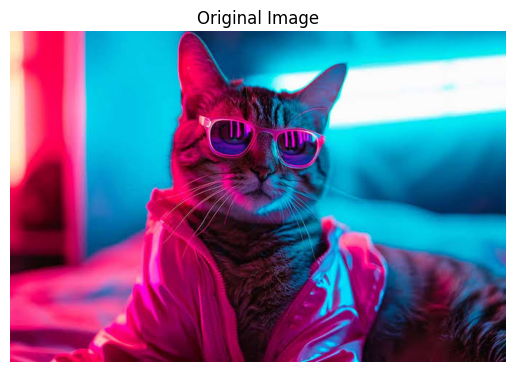

Size: (678, 452)


In [1]:
# Step 1: Libraries Check + Image Upload
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

print("Sab libraries sahi hain!")

# Image Upload karo
uploaded = files.upload()

# Pehli image ka naam lo
image_name = list(uploaded.keys())[0]
print("Tumhari image:", image_name)

# Original Image dikhao
img = Image.open(image_name)
plt.imshow(img)
plt.axis('off')
plt.title("Original Image")
plt.show()

print("Size:", img.size)

Image ki shape (Matrix): (452, 678, 3)


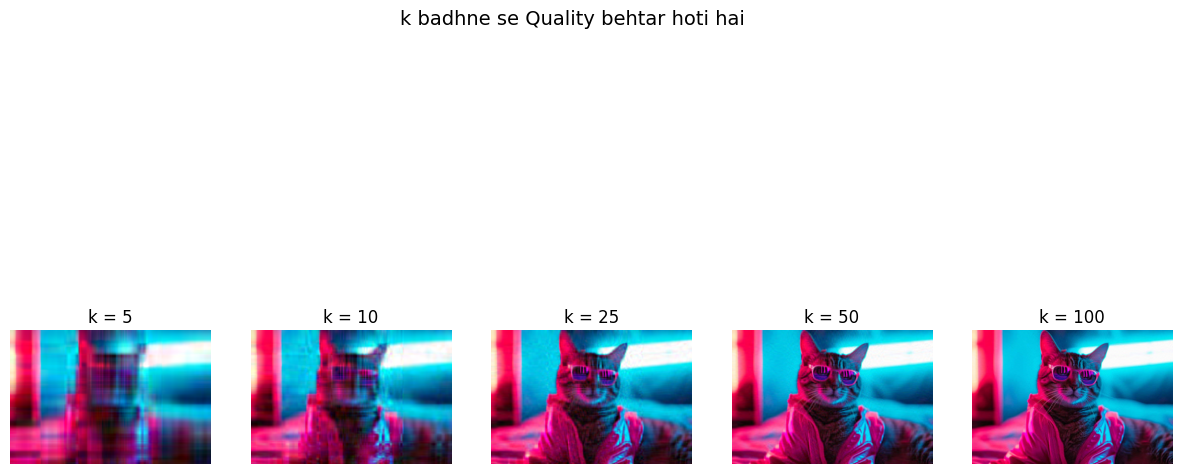

Ho gaya! k=5 sab se blur, k=100 sab se clear hoga.


In [7]:
# Step 2: SVD se Image Compress karo

# Image ko Numbers (Matrix) me badlo
img_array = np.array(img)
print("Image ki shape (Matrix):", img_array.shape)

# SVD wala Function - har color (R,G,B) pe alag se
def compress_channel(channel, k):
    U, S, Vt = np.linalg.svd(channel, full_matrices=False)
    # Sirf pehle k values rakho, baaki phenk do
    U_k = U[:, :k]
    S_k = S[:k]
    Vt_k = Vt[:k, :]
    # Wapis image banao
    compressed = U_k @ np.diag(S_k) @ Vt_k
    return np.clip(compressed, 0, 255).astype(np.uint8)

def compress_image(image, k):
    # R, G, B teeno pe SVD lagao
    r = compress_channel(image[:,:,0], k)
    g = compress_channel(image[:,:,1], k)
    b = compress_channel(image[:,:,2], k)
    return np.stack([r,g,b], axis=2)

# Ab alag alag k se test karo
k_values = [5, 10, 25, 50, 100]

plt.figure(figsize=(15, 8))
for i, k in enumerate(k_values):
    comp_img = compress_image(img_array, k)
    plt.subplot(1, 5, i+1)
    plt.imshow(comp_img)
    plt.title(f"k = {k}")
    plt.axis('off')

plt.suptitle("k badhne se Quality behtar hoti hai", fontsize=14)
plt.show()
print("Ho gaya! k=5 sab se blur, k=100 sab se clear hoga.")





In [9]:
# Step 3: Final - Slider se k badlo

from ipywidgets import interact, IntSlider

def show_compression(k):
    comp_img = compress_image(img_array, k)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original")
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(comp_img)
    plt.title(f"Compressed - k = {k}")
    plt.axis('off')
    plt.show()
    # Kitni compression hui?
    original_size = img_array.shape[0] * img_array.shape[1] * 3
    compressed_size = k * (img_array.shape[0] + img_array.shape[1] + 1) * 3
    ratio = (1 - compressed_size / original_size) * 100
    print(f"k = {k} pe {ratio:.1f}% size kam ho gaya!")

interact(show_compression, k=IntSlider(value=25, min=1, max=100, step=5, description='k ki value:'))


interactive(children=(IntSlider(value=25, description='k ki value:', min=1, step=5), Output()), _dom_classes=(…

<function __main__.show_compression(k)>